# Spatial Ecological Networks from annotated trails: Rumney Ranch A2

This notebook rebuilds, end to end, the trail-network analysis used in the ProrokLab talk (slides 38 and 39):

1. **Data and registration**: six drone images of site A2 (6 Jul to 22 Aug 2018) with hand-annotated trails, aligned to a common frame.
2. **From annotation to a binary trail map** $M$.
3. **Morphology**: closing $M_d = M \bullet B_r$ to bridge small gaps.
4. **Skeleton** $K = \mathcal{S}(M_d)$ and the neighbour count $\nu(x)$.
5. **Graph** $G=(V,E,\phi)$: nodes, edges, spur pruning, edge attributes.
6. **Network measures**: meshedness $\alpha$ and route factor $Q$.
7. **Reference graphs** on the same nodes: Delaunay triangulation $\mathcal{D}(V)$ and its minimum spanning tree $T$, plus the Voronoi duality.
8. **Temporal analysis** over the six dates and how to read it.

Each step has a short explanation of the mathematical tool it uses. Parameters are collected in one cell so they can be changed and the whole analysis re-run.

**Requirements:** `numpy scipy scikit-image networkx opencv-python skan matplotlib pillow` (tested with scikit-image 0.26, skan 0.13, networkx 3.6, OpenCV 5.0).

In [1]:
%matplotlib inline
import os, warnings
from pathlib import Path
import numpy as np, cv2, networkx as nx
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_closing, binary_dilation, distance_transform_edt
from scipy.spatial import Delaunay, Voronoi
from skimage.morphology import skeletonize, remove_small_holes
from skan import Skeleton, summarize
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'mathtext.fontset': 'cm', 'axes.spines.top': False, 'axes.spines.right': False})

def find_repo(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / 'data_acquisition').is_dir():
            return p
    return None

REPO = find_repo()
A2 = Path(os.environ.get('A2_DIR', REPO / 'data_acquisition/example_datasets/RUMNEY_RANCH_RGB/A2' if REPO else 'A2'))
assert A2.is_dir(), f'A2 folder not found: {A2} (set the A2_DIR environment variable)'

DATES  = ['07062018', '07172018', '07262018', '08062018', '08142018', '08222018']
LABELS = ['6 Jul', '17 Jul', '26 Jul', '6 Aug', '14 Aug', '22 Aug']
DAYS   = [0, 11, 20, 31, 39, 47]          # days after 6 Jul 2018
print('data folder:', A2)

data folder: /mnt/user-data/uploads/A2


### Parameters

| Symbol | Name | Value | Meaning |
|---|---|---|---|
| $W\times H$ | working resolution | 1284 × 809 px | all images are resampled to this grid |
| $d_{\max}$ | largest gap to bridge | 2 px | closing disk radius $r = d_{\max}/2$ |
| $A_{\text{hole}}$ | small-hole area | 30 px² | holes smaller than this are filled after closing |
| $n_{\min}$ | min annotation blob | 40 px | red blobs smaller than this are treated as noise |
| $\ell_{\min}$ | spur pruning length | 8 px | terminal branches shorter than this are removed |
| $\delta_{\min}$ | min pair separation for $Q$ | 50 px | pairs closer than this are skipped in the route factor |

In [2]:
W, H        = 1284, 809
D_MAX       = 2       # px, closing diameter
HOLE_AREA   = 30      # px^2
MIN_BLOB    = 40      # px
L_MIN       = 8       # px
MIN_SEP     = 50      # px
JUNCTION_MERGE = 2.5  # px, junction-junction edges shorter than this are contracted (pixel artefacts)

## 1. Data and registration

Each date has a raw drone image and an annotated copy where the ecologists drew trails in red. Two alignment problems must be solved before the trails can be compared in time.

**(a) Annotation → its own raw image.** Some annotated files were exported at a different size (17 Jul is 960 px wide instead of ~1289 px), so simply resizing would stretch the drawing. We estimate the transform with **SIFT keypoints + RANSAC**:

* SIFT finds distinctive local features in both images and describes each with a 128-D gradient histogram, invariant to scale and rotation.
* Matches are kept only if the best match is clearly better than the second best (Lowe's ratio test, 0.7).
* RANSAC repeatedly fits a **similarity transform** (rotation, uniform scale, translation, 4 parameters) to random minimal subsets of matches and keeps the model with the most inliers (reprojection error < 3 px). This makes the fit robust to wrong matches.

The red strokes are masked out of the annotated image before detecting features, so the transform is driven by the landscape only.

**(b) Each date → the first date (6 Jul).** The drone did not fly exactly the same footprint each time. We estimate a pure translation with **phase correlation**: by the Fourier shift theorem, a shift $\mathbf{t}$ in space is a phase ramp $e^{-i\,\omega\cdot\mathbf{t}}$ in frequency, so the inverse transform of the normalised cross-power spectrum
$$R(\omega)=\frac{F_1(\omega)\,F_2^*(\omega)}{|F_1(\omega)\,F_2^*(\omega)|}$$
is a peak at $\mathbf{t}$. A Hanning window reduces edge effects.

In [3]:
def load_rgb(p):
    return np.array(Image.open(p).convert('RGB'))

def red_dominant(a):
    a = a.astype(int)
    return (a[..., 0] - a[..., 1] > 60) & (a[..., 0] - a[..., 2] > 30)

sift = cv2.SIFT_create(6000)
def register_annotation(raw, ann):
    # similarity transform mapping the annotated image onto its raw image
    rm = cv2.dilate(red_dominant(ann).astype(np.uint8), np.ones((9, 9))) > 0
    k1, d1 = sift.detectAndCompute(cv2.cvtColor(ann, cv2.COLOR_RGB2GRAY), (~rm).astype(np.uint8) * 255)
    k2, d2 = sift.detectAndCompute(cv2.cvtColor(raw, cv2.COLOR_RGB2GRAY), None)
    good = [a for a, b in cv2.BFMatcher().knnMatch(d1, d2, k=2) if a.distance < 0.7 * b.distance]
    p1 = np.float32([k1[m.queryIdx].pt for m in good]); p2 = np.float32([k2[m.trainIdx].pt for m in good])
    M, inl = cv2.estimateAffinePartial2D(p1, p2, method=cv2.RANSAC, ransacReprojThreshold=3)
    return M, len(good), int(inl.sum())

raw, ann = [], []
for d in DATES:
    r = load_rgb(A2 / f'A2_{d}.PNG'); a = load_rgb(A2 / 'annotated' / f'A2_{d}_annotated.PNG')
    M, n_match, n_in = register_annotation(r, a)
    s = np.hypot(M[0, 0], M[0, 1]); rot = np.degrees(np.arctan2(M[1, 0], M[0, 0]))
    print(f'{d}: raw {r.shape[1]}x{r.shape[0]}, annotated {a.shape[1]}x{a.shape[0]}, '
          f'{n_match} matches, {n_in} inliers, scale {s:.3f}, rotation {rot:+.2f} deg, shift ({M[0,2]:.1f}, {M[1,2]:.1f})')
    aw = cv2.warpAffine(a, M, (r.shape[1], r.shape[0]), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0))
    raw.append(np.array(Image.fromarray(r).resize((W, H), Image.LANCZOS)))
    ann.append(np.array(Image.fromarray(aw).resize((W, H), Image.LANCZOS)))

07062018: raw 1282x809, annotated 1284x809, 5642 matches, 5640 inliers, scale 1.000, rotation +0.00 deg, shift (2.0, 16.0)


07172018: raw 1289x808, annotated 960x811, 4996 matches, 4996 inliers, scale 1.000, rotation -0.00 deg, shift (164.0, 0.0)


07262018: raw 1281x810, annotated 1284x810, 5940 matches, 5940 inliers, scale 1.000, rotation -0.00 deg, shift (-2.0, 0.0)


08062018: raw 1285x810, annotated 1285x810, 5352 matches, 5352 inliers, scale 1.000, rotation +0.00 deg, shift (-0.0, -0.0)


08142018: raw 1287x810, annotated 1285x811, 5175 matches, 5175 inliers, scale 1.000, rotation +0.00 deg, shift (1.0, -1.0)


08222018: raw 1283x813, annotated 1284x809, 4395 matches, 4395 inliers, scale 1.000, rotation +0.00 deg, shift (0.0, 2.0)


## 2. From annotation to a trail map $p$ and a mask $M$

The annotation is drawn in red, so the trail map is the set of pixels that are strongly red **and** differ from the raw image (so that naturally reddish ground is not picked up). For hand annotations the map is already binary, $p:\Omega\to\{0,1\}$, and the threshold step
$$M=\{x\in\Omega:\ p(x)\ge p_{\min}\}$$
is trivial ($p_{\min}=1$). With a detection network $p$ would be a probability in $[0,1]$ and $p_{\min}$ a real choice.

Blobs smaller than $n_{\min}$ pixels (connected components, 8-connectivity) are removed as annotation noise. Finally each date is shifted onto the 6 Jul frame with the phase-correlation translation.

  6 Jul: shift to 6 Jul = ( -0.0,  +0.0) px, trail pixels = 1708
 17 Jul: shift to 6 Jul = ( +3.0,  +5.9) px, trail pixels = 2336
 26 Jul: shift to 6 Jul = ( +6.4,  +8.8) px, trail pixels = 1401
  6 Aug: shift to 6 Jul = (-13.2,  -7.2) px, trail pixels = 18732
 14 Aug: shift to 6 Jul = ( +2.9,  +6.8) px, trail pixels = 19160
 22 Aug: shift to 6 Jul = ( +2.2,  +4.2) px, trail pixels = 34314


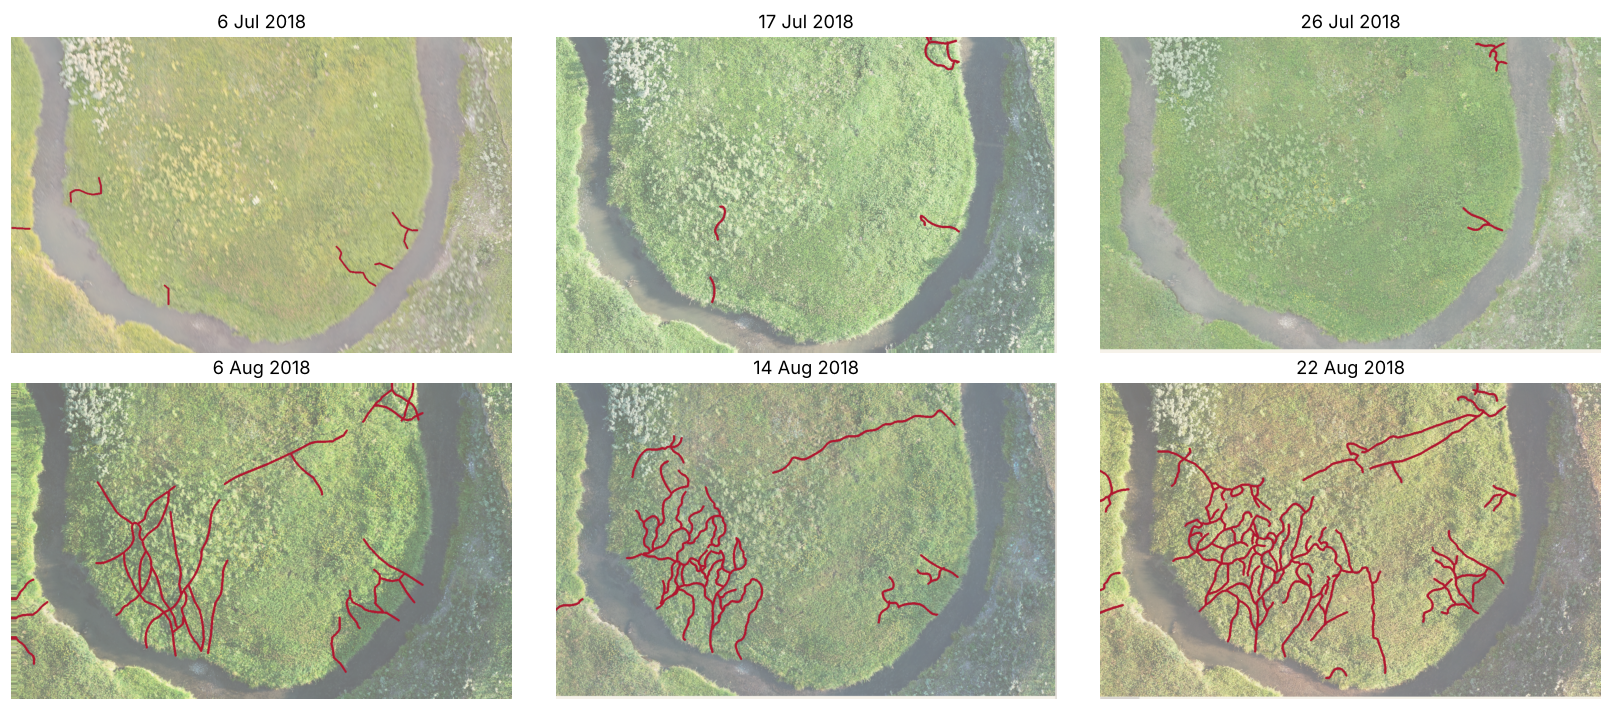

In [4]:
def drop_small(m, n=MIN_BLOB):
    k, lab, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
    return np.isin(lab, [i for i in range(1, k) if st[i, 4] >= n])

masks = []
for r, a in zip(raw, ann):
    ai, ri = a.astype(int), r.astype(int)
    m = red_dominant(a) & (np.abs(ai - ri).sum(2) > 60)
    masks.append(drop_small(m))

gray = lambda a: np.float32(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY))
win = cv2.createHanningWindow((W, H), cv2.CV_32F)
shifts = [cv2.phaseCorrelate(gray(raw[0]), gray(raw[i]), win)[0] for i in range(6)]
def translate(a, d, interp=cv2.INTER_LINEAR):
    T = np.float32([[1, 0, -d[0]], [0, 1, -d[1]]])
    return cv2.warpAffine(a, T, (W, H), flags=interp, borderMode=cv2.BORDER_REPLICATE)
raw   = [translate(raw[i], shifts[i]) for i in range(6)]
masks = [translate(masks[i].astype(np.uint8), shifts[i], cv2.INTER_NEAREST) > 0 for i in range(6)]
for l, s, m in zip(LABELS, shifts, masks):
    print(f'{l:>7}: shift to 6 Jul = ({s[0]:+5.1f}, {s[1]:+5.1f}) px, trail pixels = {m.sum()}')

fig, ax = plt.subplots(2, 3, figsize=(15, 6.5))
CR = np.array([245, 236, 218])
for i, a in enumerate(ax.flat):
    im = (raw[i] * 0.55 + CR * 0.45).astype(np.uint8); im[binary_dilation(masks[i])] = (176, 24, 48)
    a.imshow(im); a.set_title(LABELS[i] + ' 2018'); a.axis('off')
plt.tight_layout(); plt.show()

## 3. Morphological closing: $M_d = M\bullet B_r$

Mathematical morphology probes a binary set $A$ with a small shape $B$ (the *structuring element*, here a disk $B_r$ of radius $r$):

* **Dilation** $A\oplus B=\{x:\ (B+x)\cap A\neq\emptyset\}$ grows $A$ by $r$ in every direction.
* **Erosion** $A\ominus B=\{x:\ B+x\subseteq A\}$ shrinks it by $r$.
* **Closing** $A\bullet B=(A\oplus B)\ominus B$: grow then shrink back. Everything returns to its size *except* gaps and holes narrower than the disk, which are filled and stay filled.

Properties: closing is *extensive* ($A\subseteq A\bullet B$, it only adds pixels) and *idempotent* ($(A\bullet B)\bullet B=A\bullet B$). Two strokes separated by a gap $g$ are joined when dilating each side by $r$ makes them touch, i.e. $g\le 2r$; hence $r=d_{\max}/2$.

After closing, holes smaller than $A_{\text{hole}}$ are filled. This removes pinholes that would otherwise appear as tiny spurious loops in the skeleton; real trail loops are far larger and are kept.

In [5]:
def disk(r):
    R = int(np.ceil(r)); y, x = np.mgrid[-R:R + 1, -R:R + 1]
    return (x * x + y * y) <= r * r + 1e-9

def close_mask(m, d_max=D_MAX, hole_area=HOLE_AREA):
    r = d_max / 2
    out = binary_closing(np.pad(m, 25), structure=disk(r))[25:-25, 25:-25] if r >= 1 else m.copy()
    return remove_small_holes(out, area_threshold=hole_area)

closed = [close_mask(m) for m in masks]
for l, m, c in zip(LABELS, masks, closed):
    print(f'{l:>7}: added by closing = {(c & ~m).sum():4d} px')

  6 Jul: added by closing =    2 px
 17 Jul: added by closing =   32 px
 26 Jul: added by closing =   31 px
  6 Aug: added by closing =  252 px
 14 Aug: added by closing =  442 px
 22 Aug: added by closing =  752 px


## 4. Skeleton $K=\mathcal{S}(M_d)$ and neighbour count $\nu(x)$

**Skeletonisation** reduces each trail to a one-pixel-wide centreline that keeps the topology of the mask (same connected pieces, same loops). `skimage.morphology.skeletonize` uses iterative **thinning** (Zhang's algorithm in 2-D): boundary pixels are peeled off in alternating passes, but only if removing them neither disconnects the shape nor shortens an end. It stops when nothing more can be removed.

On the skeleton, the **8-neighbour count**
$$\nu(x)=|N_8(x)\cap K|$$
classifies each skeleton pixel: $\nu=1$ is an **endpoint**, $\nu=2$ is the **interior of a path**, $\nu\ge 3$ is a **junction**. This is exactly what turns a picture into a graph.

In [6]:
def nu(sk):
    k = np.ones((3, 3), np.uint8); k[1, 1] = 0
    return cv2.filter2D(sk.astype(np.uint8), -1, k, borderType=cv2.BORDER_CONSTANT) * sk

sk22 = skeletonize(closed[5]); n22 = nu(sk22)
print('22 Aug skeleton pixels:', sk22.sum(), '| endpoints (nu=1):', (n22 == 1).sum(),
      '| path (nu=2):', (n22 == 2).sum(), '| junction pixels (nu>=3):', (n22 >= 3).sum())

22 Aug skeleton pixels: 7881 | endpoints (nu=1): 80 | path (nu=2): 7496 | junction pixels (nu>=3): 305


## 5. The graph $G=(V,E,\phi)$

* **Nodes** $V=\{x\in K:\ \nu(x)\neq 2\}$: endpoints and junctions.
* **Edges** $E$: the skeleton paths $\gamma_e$ between two nodes. We use [`skan`](https://skeleton-analysis.org), which walks the skeleton and returns every branch with its pixel path and length.
* **Spur pruning**: a terminal branch (one end is an endpoint) shorter than $\ell_{\min}$ is almost always an annotation wiggle, not a trail. Such branches are removed iteratively until none is left. Only terminal branches are pruned, so loops are never opened.
* **Clean-up**: junctions made of several adjacent pixels produce tiny junction-to-junction edges ($\le$ 2.5 px); these are contracted into one node. Nodes left with degree 2 after pruning are merged into a single edge.

Each edge stores its **attributes** $\phi(e)=(\ell_e,\tau_e,w_e,\bar p_e)$:

* length $\ell_e$: arc length along the skeleton (diagonal steps count $\sqrt2$);
* tortuosity $\tau_e=\ell_e/c_e\ge 1$, with $c_e$ the straight chord between the two ends;
* width $w_e=2\,\overline{\mathrm{EDT}}$: twice the mean Euclidean distance transform of the mask along the path (distance from the centreline to the trail border);
* $\bar p_e$: mean of $p$ along the path. For binary annotations this is 1 and is not computed here.

In [7]:
def build_graph(mask, l_min=L_MIN):
    dt = distance_transform_edt(mask)
    sk = Skeleton(skeletonize(mask), spacing=1, keep_images=True)
    while l_min > 0:                                   # iterative spur pruning
        s = summarize(sk, separator='_')
        cut = s.index[(s.branch_type == 1) & (s.branch_distance < l_min)].tolist()
        if not cut: break
        sk = sk.prune_paths(cut)
    s = summarize(sk, separator='_')
    G = nx.MultiGraph()
    for i, row in s.iterrows():
        pth = sk.path_coordinates(i).astype(int)
        u, v = int(row.node_id_src), int(row.node_id_dst)
        for nid, (y, x) in [(u, pth[0]), (v, pth[-1])]: G.add_node(nid, y=float(y), x=float(x))
        L, ch = float(row.branch_distance), float(row.euclidean_distance)
        G.add_edge(u, v, length=L, chord=ch, tort=L / ch if ch > 0 else np.inf,
                   width=float(2 * dt[pth[:, 0], pth[:, 1]].mean()), path=pth)
    changed = True                                     # contract pixel-level junction clusters
    while changed:
        changed = False
        for u, v, d in list(G.edges(data=True)):
            if u != v and d['length'] <= JUNCTION_MERGE and G.degree(u) >= 3 and G.degree(v) >= 3:
                G = nx.contracted_nodes(G, u, v, self_loops=False); changed = True; break
    for n in [n for n in list(G.nodes) if G.degree(n) == 2 and len(set(G.neighbors(n))) == 2]:
        (a, da), (b, db) = [(nb, list(G.get_edge_data(n, nb).values())[0]) for nb in G.neighbors(n)]
        L = da['length'] + db['length']
        ch = float(np.hypot(G.nodes[a]['x'] - G.nodes[b]['x'], G.nodes[a]['y'] - G.nodes[b]['y']))
        G.add_edge(a, b, length=L, chord=ch, tort=L / ch if ch > 0 else np.inf,
                   width=(da['width'] * da['length'] + db['width'] * db['length']) / L,
                   path=np.vstack([da['path'], db['path']]))
        G.remove_node(n)
    return G

def simple(M):
    # simple graph: drop self-loops, keep the shortest of parallel edges
    G = nx.Graph()
    for u, v, d in M.edges(data=True):
        if u == v: continue
        if G.has_edge(u, v) and G[u][v]['length'] <= d['length']: continue
        G.add_edge(u, v, **d)
    for n in G: G.nodes[n].update(M.nodes[n])
    return G

graphs = [simple(build_graph(c)) for c in closed]
for l, G in zip(LABELS, graphs):
    k = np.array([d for _, d in G.degree()])
    print(f'{l:>7}: |V| = {G.number_of_nodes():3d}, |E| = {G.number_of_edges():3d}, pieces C = {nx.number_connected_components(G):2d}, '
          f'endpoints = {(k == 1).sum():3d}, forks = {(k == 3).sum():3d}, crossings (k>=4) = {(k >= 4).sum()}')

  6 Jul: |V| =  14, |E| =   8, pieces C =  6, endpoints =  13, forks =   1, crossings (k>=4) = 0
 17 Jul: |V| =  14, |E| =  10, pieces C =  5, endpoints =  11, forks =   3, crossings (k>=4) = 0
 26 Jul: |V| =  12, |E| =  10, pieces C =  2, endpoints =   8, forks =   4, crossings (k>=4) = 0
  6 Aug: |V| =  65, |E| =  65, pieces C =  9, endpoints =  33, forks =  31, crossings (k>=4) = 1
 14 Aug: |V| =  75, |E| =  81, pieces C =  6, endpoints =  31, forks =  41, crossings (k>=4) = 1
 22 Aug: |V| = 172, |E| = 179, pieces C = 10, endpoints =  80, forks =  86, crossings (k>=4) = 4


### The pipeline on a window of the 22 Aug map (as on slide 38)

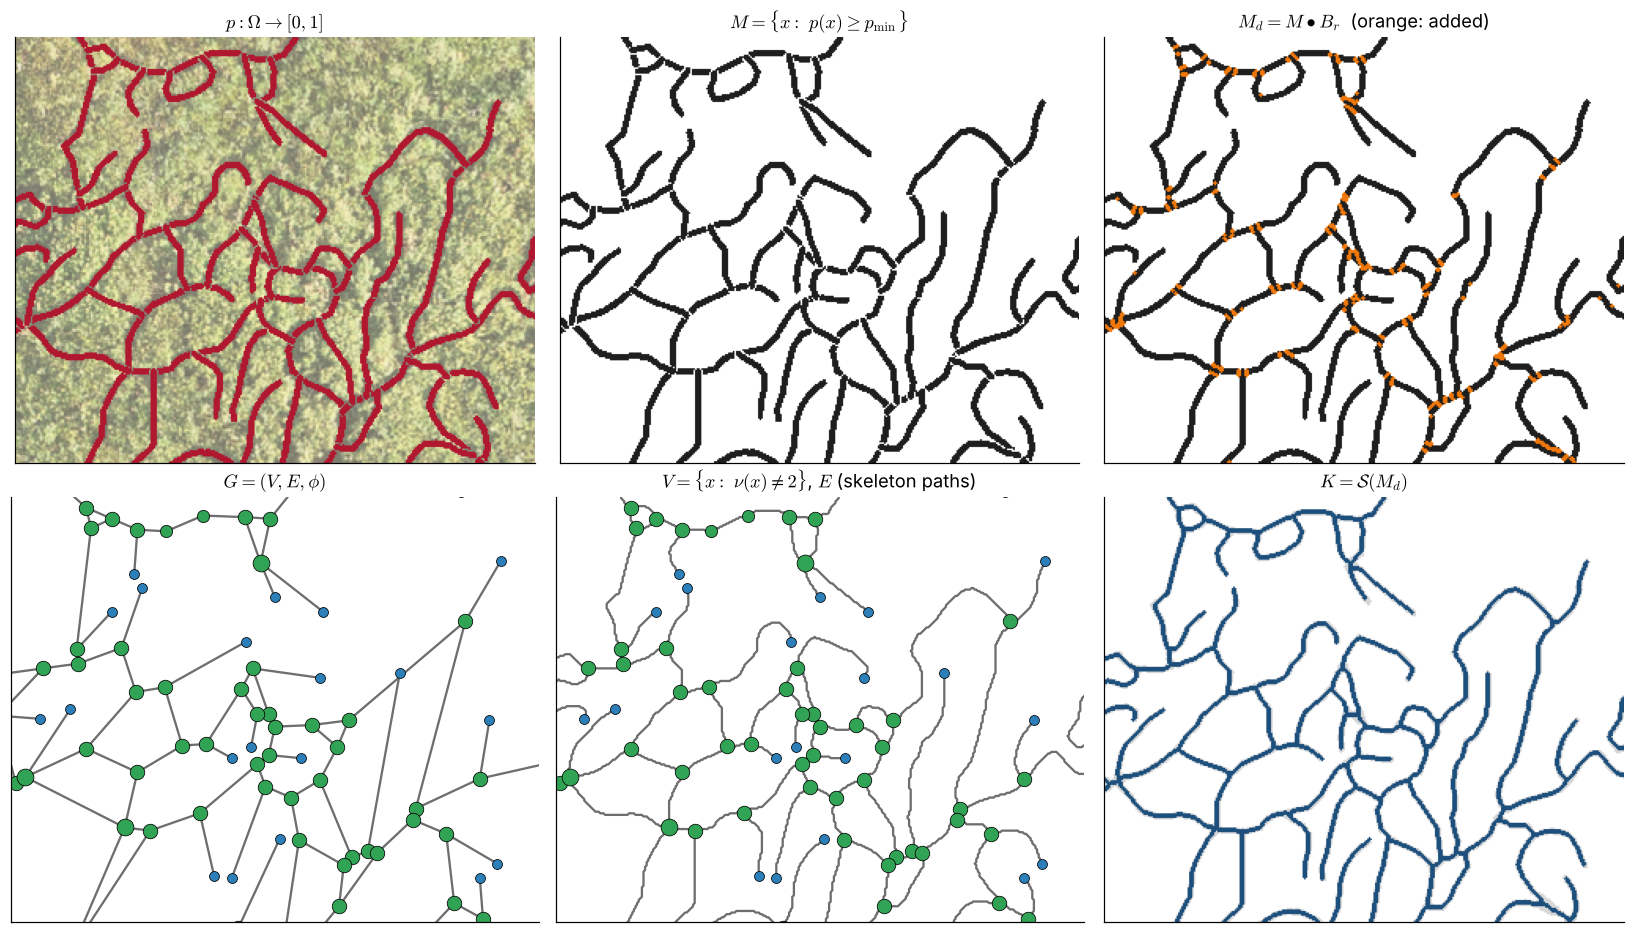

In [8]:
X0, Y0, X1, Y1 = 240, 250, 570, 520          # window used for the slide figures
def crop(a): return a[Y0:Y1, X0:X1]
G22 = graphs[5]
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))
im = (raw[5] * 0.55 + CR * 0.45).astype(np.uint8); im[masks[5]] = (176, 24, 48)
ax[0, 0].imshow(crop(im)); ax[0, 0].set_title(r'$p:\Omega\to[0,1]$')
b = np.full(crop(masks[5]).shape + (3,), 255, np.uint8); b[crop(masks[5])] = 30
ax[0, 1].imshow(b); ax[0, 1].set_title(r'$M=\{x:\ p(x)\geq p_{\min}\}$')
c = b.copy(); add = crop(closed[5]) & ~crop(masks[5]); c[binary_dilation(add)] = (240, 120, 10)
ax[0, 2].imshow(c); ax[0, 2].set_title(r'$M_d=M\bullet B_r$  (orange: added)')
d = np.full(b.shape, 255, np.uint8); d[crop(closed[5])] = 215; d[binary_dilation(crop(sk22))] = (29, 79, 124)
ax[1, 2].imshow(d); ax[1, 2].set_title(r'$K=\mathcal{S}(M_d)$')
col = {1: '#2c7fb8'}
for a, curved in [(ax[1, 1], True), (ax[1, 0], False)]:
    a.set_facecolor('white')
    for u, v, e in G22.edges(data=True):
        if curved: a.plot(e['path'][:, 1] - X0, e['path'][:, 0] - Y0, color='#6e6e6e', lw=1.5)
        else: a.plot([G22.nodes[u]['x'] - X0, G22.nodes[v]['x'] - X0], [G22.nodes[u]['y'] - Y0, G22.nodes[v]['y'] - Y0], color='#6e6e6e', lw=1.5)
    for n, k in G22.degree():
        a.plot(G22.nodes[n]['x'] - X0, G22.nodes[n]['y'] - Y0, 'o', ms=5 + 1.5 * k, color=col.get(k, '#31a354'), mec='k', mew=.5)
    a.set_xlim(0, X1 - X0); a.set_ylim(Y1 - Y0, 0)
ax[1, 1].set_title(r'$V=\{x:\ \nu(x)\neq2\}$, $E$ (skeleton paths)'); ax[1, 0].set_title(r'$G=(V,E,\phi)$')
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

### Sensitivity to $\ell_{\min}$ and $d_{\max}$ (22 Aug)

A pre-processing choice should not drive the result. The counts below show how the graph reacts to the two main parameters. The number of independent loops $|E|-|V|+C$ is the quantity that meshedness relies on.

In [9]:
def loops(G): return G.number_of_edges() - G.number_of_nodes() + nx.number_connected_components(G)
rows = []
for lm in [0, 4, 8, 16, 24, 32]:
    G = simple(build_graph(closed[5], l_min=lm)); rows.append(('l_min', lm, G.number_of_nodes(), loops(G)))
for dm in [1, 2, 4, 6, 10]:
    G = simple(build_graph(close_mask(masks[5], d_max=dm))); rows.append(('d_max', dm, G.number_of_nodes(), loops(G)))
print(f"{'param':>6} {'value':>5} {'|V|':>5} {'loops':>6}")
for r in rows: print(f'{r[0]:>6} {r[1]:>5} {r[2]:>5} {r[3]:>6}')

 param value   |V|  loops
 l_min     0   172     17
 l_min     4   172     17
 l_min     8   172     17
 l_min    16   165     17
 l_min    24   156     17
 l_min    32   134     16
 d_max     1   173      3
 d_max     2   172     17
 d_max     4   172     18
 d_max     6   175     21
 d_max    10   172     27


**Reading the sweep.** Spur pruning removes endpoints but never touches the loops, as intended. The closing is different: without it ($d_{\max}=1$, no closing) only a few loops survive, while from $d_{\max}=2$ onwards the count is stable for a while and then grows slowly. Hand-drawn strokes meet at junctions with 1–2 px gaps, so a minimal closing is needed to reconnect them; larger disks start to merge trails that were drawn as separate. $d_{\max}=2$ px is the smallest value that reconnects the drawn junctions. Any loop count should be reported together with this choice.

## 6. Network measures

### Meshedness $\alpha$
For a planar graph with $|V|$ nodes, $|E|$ edges and $C$ connected pieces, Euler's formula gives the number of faces $F=|E|-|V|+C+1$, so the number of **independent loops** (the cyclomatic number) is
$$\mu=|E|-|V|+C .$$
A planar graph can have at most $3|V|-6$ edges (every face is a triangle), i.e. at most $2|V|-5$ independent loops. Meshedness is the fraction of that maximum:
$$\alpha=\frac{|E|-|V|+C}{2|V|-5}\in[0,1].$$
$\alpha=0$ for a tree (or a forest), $\alpha\approx1$ for a full triangulation. It is the planar replacement of the clustering coefficient, which is almost zero in sparse planar networks because triangles are rare. Using $C$ instead of 1 matters when the annotation is fragmented.

### Route factor $Q$
For two nodes $i,j$ in the same piece, $d_G(i,j)$ is the length of the **shortest path** along the network (Dijkstra's algorithm, edge weights = lengths). The route factor of the pair is $d_G(i,j)/\|x_i-x_j\|\ge1$, and
$$Q=\operatorname*{median}_{i,j}\ \frac{d_G(i,j)}{\|x_i-x_j\|},$$
over all pairs in the same piece more than $\delta_{\min}$ apart (very close pairs give unstable ratios; the median is robust to a few very roundabout pairs). $Q=1$ means the network offers straight routes. This is the "directness" $Q(i,j)=d_R/d_E$ of Anderson and Dragićević (2020).

Two versions are computed:
* **straight edges**: each edge weighted by its chord $c_e$; this is comparable with the reference graphs, whose edges are straight;
* **along the path**: each edge weighted by its true length $\ell_e$; the gap between the two is due to tortuosity $\tau_e$.

In [10]:
def xy_of(G): return {n: np.array([G.nodes[n]['x'], G.nodes[n]['y']]) for n in G}

def meshedness(G):
    N, E, C = G.number_of_nodes(), G.number_of_edges(), nx.number_connected_components(G)
    return (E - N + C) / (2 * N - 5) if N > 2 else np.nan

def route_factor(G, xy, weight='length', min_sep=MIN_SEP):
    vals = []
    for comp in nx.connected_components(G):
        Hc = G.subgraph(comp)
        dl = dict(nx.all_pairs_dijkstra_path_length(Hc, weight=weight))
        for a in Hc:
            for b in Hc:
                if a < b:
                    e = np.linalg.norm(xy[a] - xy[b])
                    if e > min_sep: vals.append(dl[a][b] / e)
    return float(np.median(vals)) if vals else np.nan

def with_chords(G):
    xy = xy_of(G); S = G.copy()
    for u, v in S.edges(): S[u][v]['chord_w'] = float(np.linalg.norm(xy[u] - xy[v]))
    return S

## 7. Reference graphs on the same nodes

A measure alone is hard to read. We compare the trails with two graphs built on **the same nodes and the same connected pieces**, with straight edges:

* **Delaunay triangulation $\mathcal{D}(V)$**: connect the points into triangles such that **no point lies inside the circumcircle of any triangle**. Among all triangulations it maximises the smallest angle (no slivers). It is planar, has $3N-3-h$ edges ($h$ = points on the convex hull), and represents the *most connected* planar network: $\alpha$ close to 1 and $Q$ close to 1.
* **Minimum spanning tree $T=\mathrm{MST}(\mathcal{D}(V))$**: the set of edges of least total length that connects all nodes, with no loop ($N-1$ edges). Since the Euclidean MST is always contained in the Delaunay triangulation, computing it on $\mathcal{D}(V)$ gives the true Euclidean MST. It is the *cheapest* network: $\alpha=0$ and long detours.

**Why per piece?** The trails on early dates are fragmented. Triangulating across pieces would add connections the animals never made, so the gap to the reference would mix "missing loops" with "missing connections". Per piece, the gap measures only the loops.

**Voronoi duality.** The Voronoi partition gives each node the region of space closer to it than to any other node. Two nodes are Delaunay neighbours exactly when their Voronoi cells share a border; each Delaunay edge crosses that border at a right angle; and the corner where three cells meet is the centre of the circumcircle of the corresponding triangle. Delaunay is "who are my natural neighbours", Voronoi is "which ground do I own".

In [11]:
def references(G):
    xy = xy_of(G); D = nx.Graph(); T = nx.Graph()
    D.add_nodes_from(G); T.add_nodes_from(G)
    for comp in nx.connected_components(G):
        nodes = list(comp); P = np.array([xy[n] for n in nodes]); K = nx.Graph(); K.add_nodes_from(nodes)
        if len(nodes) >= 3:
            try:
                for s in Delaunay(P).simplices:
                    for a, b in [(0, 1), (1, 2), (0, 2)]:
                        K.add_edge(nodes[s[a]], nodes[s[b]], length=float(np.linalg.norm(P[s[a]] - P[s[b]])))
            except Exception:
                pass   # collinear points: fall back below
        if K.number_of_edges() == 0:
            for a in range(len(nodes)):
                for b in range(a + 1, len(nodes)):
                    K.add_edge(nodes[a], nodes[b], length=float(np.linalg.norm(P[a] - P[b])))
        D.add_edges_from(K.edges(data=True))
        T.add_edges_from(nx.minimum_spanning_tree(K, weight='length').edges(data=True))
    for g in (D, T):
        for n in g: g.nodes[n].update(G.nodes[n])
    return D, T

### Illustration on the slide-38 window (largest connected piece)

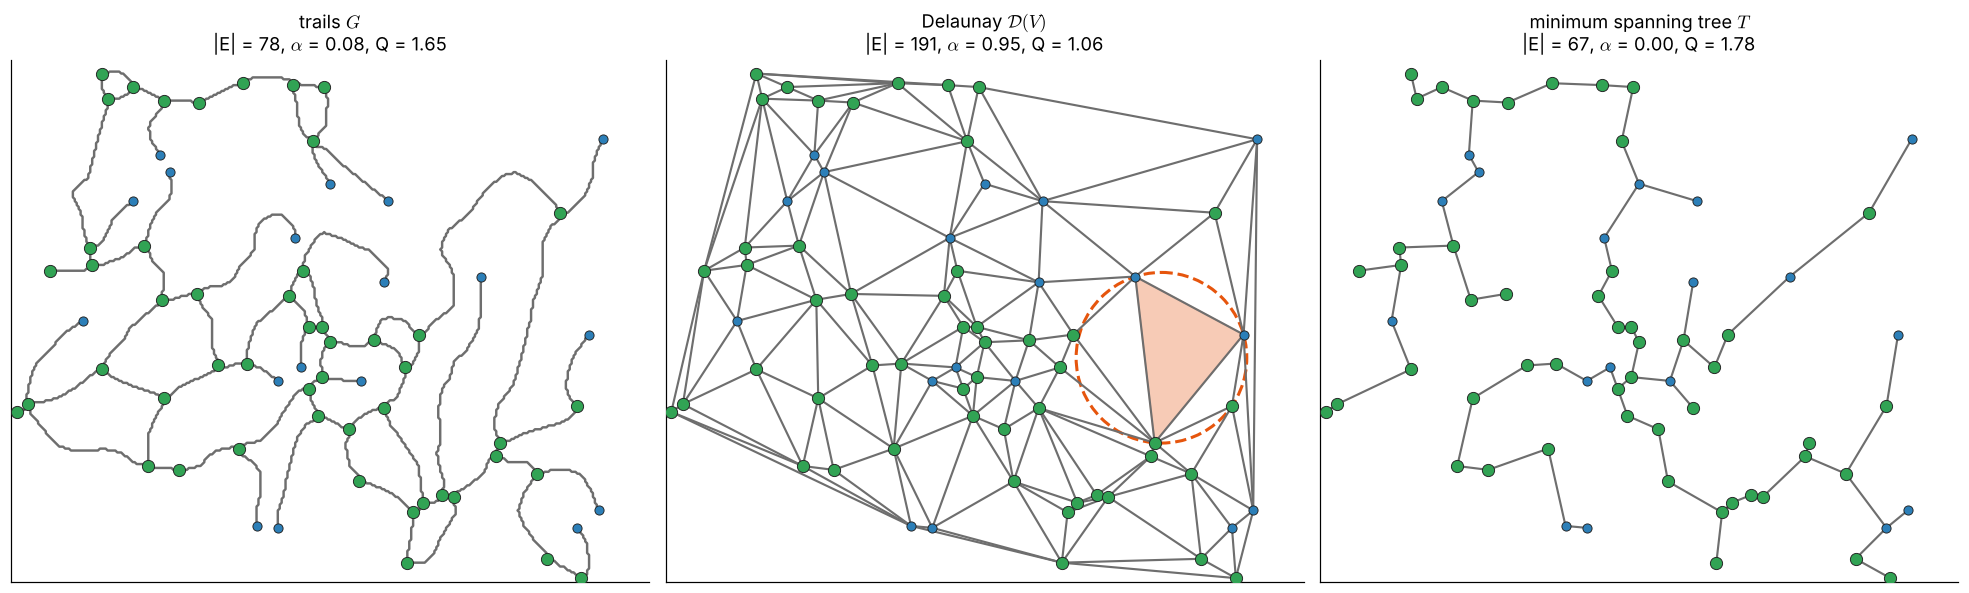

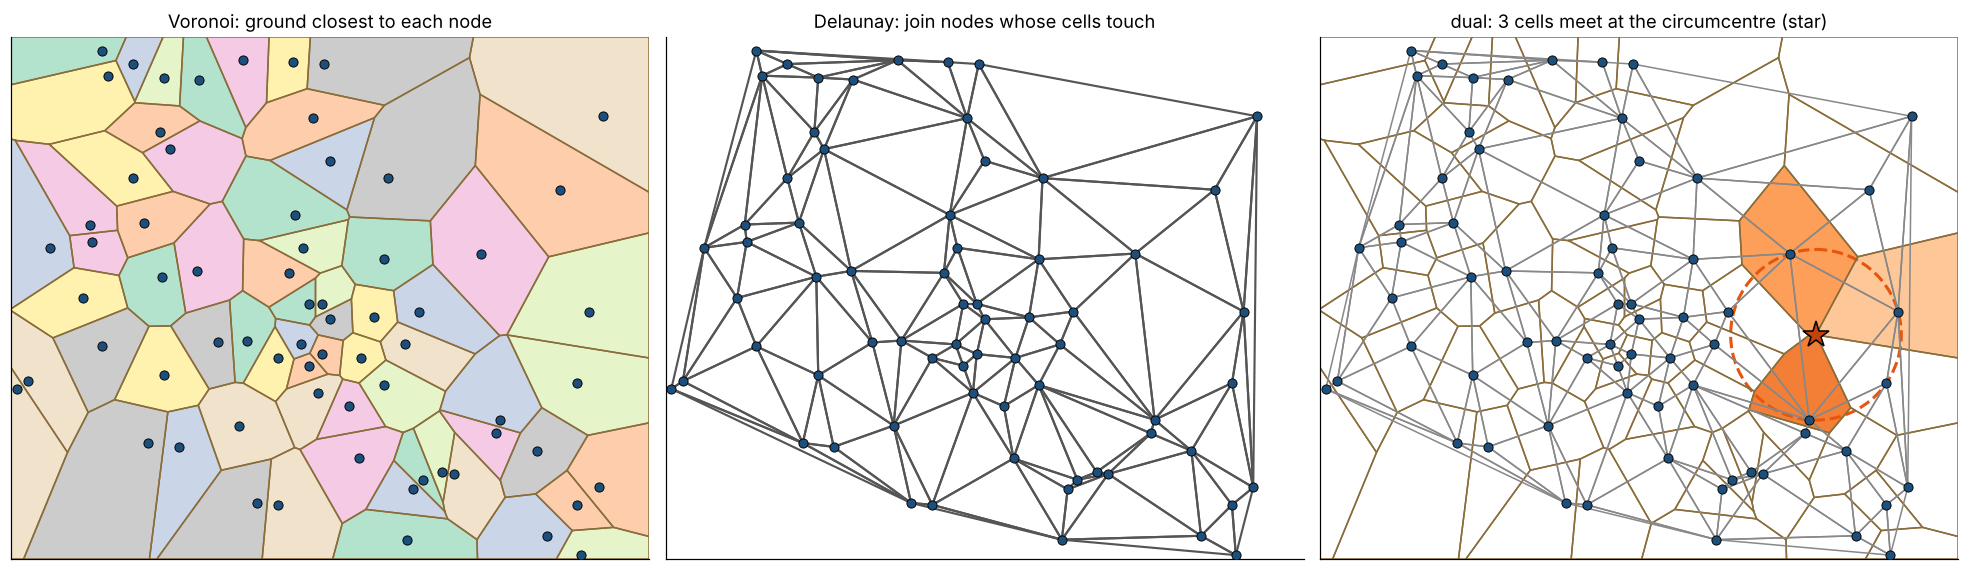

In [12]:
Hw = G22.subgraph([n for n in G22 if X0 <= G22.nodes[n]['x'] < X1 and Y0 <= G22.nodes[n]['y'] < Y1]).copy()
Hw = Hw.subgraph(max(nx.connected_components(Hw), key=len)).copy()   # drop endpoints cut by the window
xyw = xy_of(Hw); Dw, Tw = references(Hw)
deg = dict(G22.degree())

def circumcircle(A, B, C):
    d = 2 * (A[0] * (B[1] - C[1]) + B[0] * (C[1] - A[1]) + C[0] * (A[1] - B[1]))
    ux = ((A @ A) * (B[1] - C[1]) + (B @ B) * (C[1] - A[1]) + (C @ C) * (A[1] - B[1])) / d
    uy = ((A @ A) * (C[0] - B[0]) + (B @ B) * (A[0] - C[0]) + (C @ C) * (B[0] - A[0])) / d
    return np.array([ux, uy]), float(np.linalg.norm(A - [ux, uy]))

nodes = list(Hw); P = np.array([xyw[n] for n in nodes]); tri = Delaunay(P)
best = None                                                    # a large, fully visible triangle for the picture
for s in tri.simplices:
    c, R = circumcircle(*P[s])
    ok = (c[0] - R > X0 + 4) and (c[0] + R < X1 - 4) and (c[1] - R > Y0 + 30) and (c[1] + R < Y1 - 4)
    if ok and R < 75 and (best is None or R > best[2]): best = (s, c, R)
s_hi, c_hi, R_hi = best

def draw_nodes(a):
    for n in Hw:
        k = deg[n]; a.plot(*xyw[n], 'o', ms=6 if k == 1 else 8, color='#2c7fb8' if k == 1 else '#31a354', mec='#222', mew=.6, zorder=5)

fig, ax = plt.subplots(1, 3, figsize=(18, 6.3))
for a, g, title in zip(ax, [Hw, Dw, Tw], ['trails $G$', r'Delaunay $\mathcal{D}(V)$', 'minimum spanning tree $T$']):
    for u, v, e in g.edges(data=True):
        if g is Hw: a.plot(e['path'][:, 1], e['path'][:, 0], color='#6e6e6e', lw=1.6)
        else: a.plot(*np.array([xyw[u], xyw[v]]).T, color='#6e6e6e', lw=1.4)
    draw_nodes(a); a.set_xlim(X0, X1); a.set_ylim(Y1, Y0); a.set_aspect('equal'); a.set_xticks([]); a.set_yticks([])
    Q_ = route_factor(with_chords(g), xyw, weight='chord_w')
    a.set_title(title + f'\n|E| = {g.number_of_edges()}, ' + r'$\alpha$' + f' = {meshedness(g):.2f}, Q = {Q_:.2f}')
ax[1].fill(*P[s_hi].T, color='#e6550d', alpha=.3); ax[1].add_patch(plt.Circle(c_hi, R_hi, fill=False, ls='--', lw=2, color='#e6550d'))
plt.tight_layout(); plt.show()

# Voronoi duality, bounded to the window by mirroring the points across its four sides
Mirr = np.vstack([P, np.c_[2 * X0 - P[:, 0], P[:, 1]], np.c_[2 * X1 - P[:, 0], P[:, 1]], np.c_[P[:, 0], 2 * Y0 - P[:, 1]], np.c_[P[:, 0], 2 * Y1 - P[:, 1]]])
vor = Voronoi(Mirr); pal = plt.get_cmap('Pastel2')
fig, ax = plt.subplots(1, 3, figsize=(18, 6.3))
for i in range(len(P)):
    poly = vor.vertices[vor.regions[vor.point_region[i]]]
    ax[0].fill(*poly.T, color=pal(i % 8), lw=0); ax[0].plot(*np.vstack([poly, poly[:1]]).T, color='#8a6d3b', lw=1)
    ax[2].plot(*np.vstack([poly, poly[:1]]).T, color='#8a6d3b', lw=1)
for k, i in enumerate(s_hi):
    poly = vor.vertices[vor.regions[vor.point_region[i]]]
    ax[2].fill(*poly.T, color=['#f16913', '#fd8d3c', '#fdbe85'][k], alpha=.85, lw=0)
for s in tri.simplices:
    for a_, b_ in [(0, 1), (1, 2), (0, 2)]:
        ax[1].plot(*P[[s[a_], s[b_]]].T, color='#555', lw=1.4); ax[2].plot(*P[[s[a_], s[b_]]].T, color='#888', lw=1)
ax[2].add_patch(plt.Circle(c_hi, R_hi, fill=False, ls='--', lw=2, color='#e6550d')); ax[2].plot(*c_hi, '*', ms=18, color='#c0440a', mec='k')
for a, t in zip(ax, ['Voronoi: ground closest to each node', 'Delaunay: join nodes whose cells touch', 'dual: 3 cells meet at the circumcentre (star)']):
    a.plot(P[:, 0], P[:, 1], 'o', ms=6, color='#1d4f7c', mec='k', mew=.6, zorder=5)
    a.set_xlim(X0, X1); a.set_ylim(Y1, Y0); a.set_aspect('equal'); a.set_xticks([]); a.set_yticks([]); a.set_title(t)
plt.tight_layout(); plt.show()

## 8. Temporal analysis over the six dates

For each date we compute $\alpha$ and $Q$ for the trails and for the two references, on the whole site. Dates with fewer than 20 nodes are flagged: on those graphs the measures are dominated by a handful of fragments.

To read $Q$ against the band, the **position in the band** is
$$\rho=\frac{Q_{\text{trails}}-Q_{\mathcal{D}}}{Q_T-Q_{\mathcal{D}}},$$
with 0 at the triangulation (mesh-like directness) and 1 at the tree.

In [13]:
res = []
for i, G in enumerate(graphs):
    xy = xy_of(G); S = with_chords(G); D, T = references(G)
    r = dict(date=LABELS[i], N=G.number_of_nodes(), E=G.number_of_edges(), C=nx.number_connected_components(G), loops=loops(G),
             alpha=meshedness(G), alpha_D=meshedness(D), alpha_T=meshedness(T),
             Q_path=route_factor(G, xy, 'length'), Q_straight=route_factor(S, xy, 'chord_w'),
             Q_D=route_factor(D, xy, 'length'), Q_T=route_factor(T, xy, 'length'))
    r['rho'] = (r['Q_straight'] - r['Q_D']) / (r['Q_T'] - r['Q_D']) if r['Q_T'] > r['Q_D'] else np.nan
    res.append(r)
hdr = ['date', 'N', 'E', 'C', 'loops', 'alpha', 'alpha_D', 'alpha_T', 'Q_straight', 'Q_path', 'Q_D', 'Q_T', 'rho']
print(' '.join(f'{h:>10}' for h in hdr))
for r in res:
    print(' '.join(f'{r[h]:>10.3f}' if isinstance(r[h], float) else f'{r[h]:>10}' for h in hdr))

      date          N          E          C      loops      alpha    alpha_D    alpha_T Q_straight     Q_path        Q_D        Q_T        rho
     6 Jul         14          8          6          0      0.000      0.130      0.000      1.030      1.194      1.000      1.030      1.000
    17 Jul         14         10          5          1      0.043      0.217      0.000      1.016      1.282      1.000      1.109      0.148
    26 Jul         12         10          2          0      0.000      0.684      0.000      1.144      1.307      1.000      1.240      0.598
     6 Aug         65         65          9          9      0.072      0.632      0.000      1.111      1.212      1.030      1.340      0.260
    14 Aug         75         81          6         12      0.083      0.779      0.000      1.385      1.636      1.050      1.476      0.786
    22 Aug        172        179         10         17      0.050      0.844      0.000      1.593      1.777      1.052      1.694      0.842

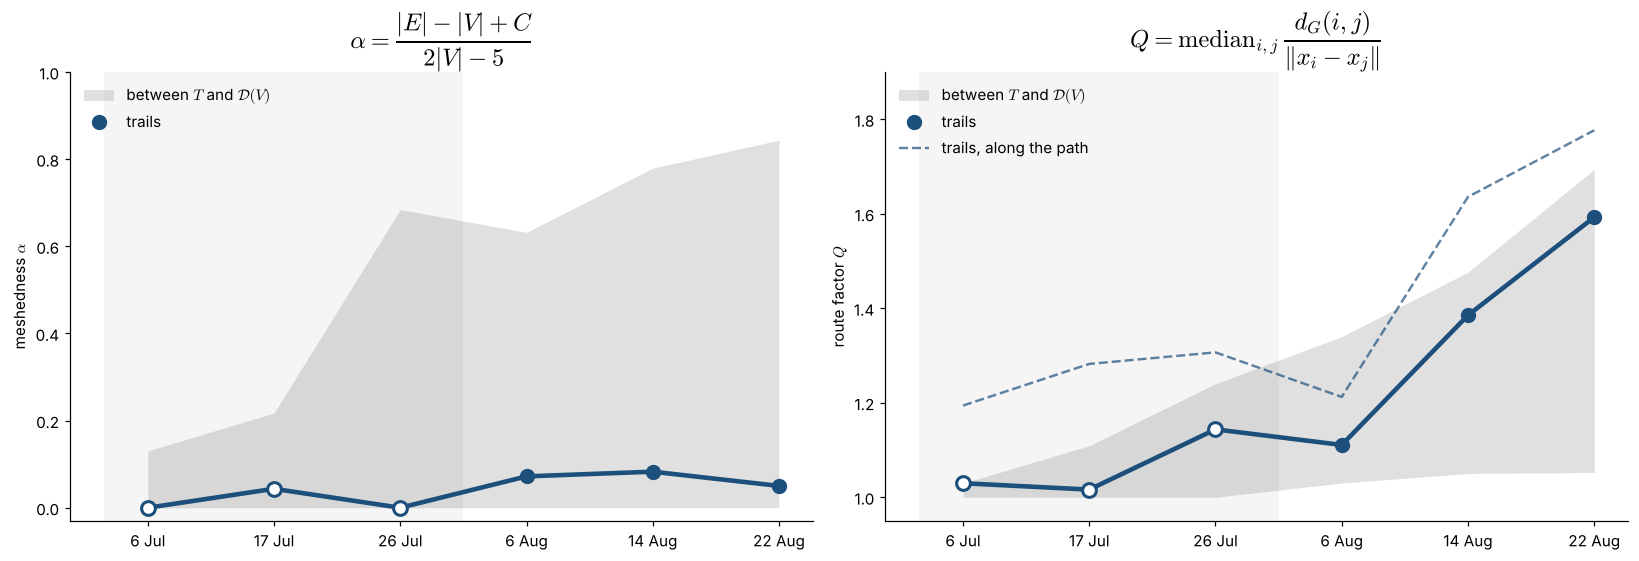

In [14]:
x = np.arange(6); early = np.array([r['N'] < 20 for r in res]); BL = '#1d4f7c'; GR = '#9a9a9a'
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
def panel(a, y, lo, hi, ylim, ylabel):
    a.fill_between(x, lo, hi, color=GR, alpha=.3, lw=0, label=r'between $T$ and $\mathcal{D}(V)$')
    a.plot(x, y, color=BL, lw=3, zorder=3)
    y = np.array(y); a.plot(x[~early], y[~early], 'o', color=BL, ms=9, zorder=4, label='trails')
    a.plot(x[early], y[early], 'o', mfc='white', mec=BL, mew=2, ms=9, zorder=4)
    a.axvspan(-.35, early.sum() - .5, color='k', alpha=.04, lw=0)
    a.set_xticks(x); a.set_xticklabels(LABELS); a.set_ylim(*ylim); a.set_ylabel(ylabel)
panel(ax[0], [r['alpha'] for r in res], [r['alpha_T'] for r in res], [r['alpha_D'] for r in res], (-.03, 1), r'meshedness $\alpha$')
panel(ax[1], [r['Q_straight'] for r in res], [r['Q_D'] for r in res], [r['Q_T'] for r in res], (.95, 1.9), r'route factor $Q$')
ax[1].plot(x, [r['Q_path'] for r in res], '--', color=BL, lw=1.6, alpha=.7, label='trails, along the path')
ax[0].set_title(r'$\alpha=\dfrac{|E|-|V|+C}{2|V|-5}$', fontsize=16)
ax[1].set_title(r'$Q=\mathrm{median}_{i,j}\,\dfrac{d_G(i,j)}{\|x_i-x_j\|}$', fontsize=16)
for a in ax: a.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

## 9. How to read the results

* **Loops.** The trails do close loops (the loop count grows over the season), but far fewer than the triangulation on the same nodes allows: $\alpha$ stays below about 0.1 while $\alpha_{\mathcal{D}}$ reaches 0.8 or more. The network is branching, not meshed.
* **Directness.** With straight edges, $Q$ of the trails lies inside the band. Its position $\rho$ moves from the mesh end towards the tree end as the network grows: the animals connect more ground, but do not add the shortcuts a planned network would add.
* **Wiggle.** $Q$ along the path is systematically higher than with straight edges; the difference is the tortuosity of the individual trails, stored per edge as $\tau_e$.
* **Early dates.** Before August the graphs have fewer than 20 nodes in several fragments, so their values should not be interpreted.
* **Small world?** Not applicable: trail networks are planar and embedded, so there are no long-range shortcuts, clustering is near zero by construction, and path length grows like $\sqrt N$ as in a lattice. For planar networks the meaningful axis is tree ↔ mesh, which is what $\alpha$ and $Q$ measure (Anderson and Dragićević, 2020; Buhl et al., 2006).
* **Uses.** These curves are the summary statistics that a simulated landscape must reproduce: the same graph pipeline is applied to the simulator output, and the distance between the two sets of statistics is the loss for learning the behavioural policy.

### References
* Anderson, T. and Dragićević, S. (2020). Complex spatial networks: theory and geospatial applications. *Geography Compass* 14(9), e12502.
* Buhl, J. et al. (2006). Topological patterns in street networks of self-organized urban settlements. *Eur. Phys. J. B* 49, 513–522.
* Jacoby, D. M. P. and Freeman, R. (2016). Emerging network-based tools in movement ecology. *Trends Ecol. Evol.* 31(4), 301–314.
* Zhang, T. Y. and Suen, C. Y. (1984). A fast parallel algorithm for thinning digital patterns. *Commun. ACM* 27(3), 236–239.
* Nunez-Iglesias, J. et al. (2018). A new Python library to analyse skeleton images confirms malaria parasite remodelling of the red blood cell membrane skeleton (skan). *PeerJ* 6, e4312.